# Results, discussion and conclusion

## Setup

In [1]:
import os, sys, json, glob
from pathlib import Path
from collections import Counter

IN_COLAB = "google.colab" in sys.modules
if not Path("ner").exists() and Path("../ner").exists():
    os.chdir("..")   # parts/ notebooks run from the repository root
if IN_COLAB and not Path("ner").exists():
    !git clone -b final-submission https://github.com/lofty14/bert-ner-baseline.git
    %cd bert-ner-baseline
    !pip -q install transformers==5.22.0 accelerate==1.15.0 seqeval==1.2.2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT))
pd.set_option("display.precision", 2)
print("repo root:", ROOT)

repo root: /Users/chonglichen/UNSW/COMP9444/group_project


## Results
*Owner: Alex Shen. Rubric (3 marks): results clearly shown and evaluated with appropriate metrics; graphs; comparison
with previous methods / state of the art.*

The table is built from the per-seed metric files. Test scores are taken at the epoch selected on the dev set.

In [2]:
METRIC_DIRS = ["results/metrics", "dapt/results/metrics"]   # per-seed JSON written by ner.train
EXPECTED = ["bert", "biobert", "pubmedbert", "bert+dapt1ep", "bert+dapt3ep"]

runs = []
for d in METRIC_DIRS:
    for f in sorted(glob.glob(f"{d}/*_seed*.json")):
        label = Path(f).stem.rsplit("_seed", 1)[0]
        if label.startswith("control"):
            continue
        m = json.load(open(f))
        s = m["test"]["strict"]
        runs.append({"model": label, "seed": m["seed"], "P": 100 * s["precision"],
                     "R": 100 * s["recall"], "F1": 100 * s["f1"]})
runs = pd.DataFrame(runs).drop_duplicates(["model", "seed"])

missing = [m for m in EXPECTED if m not in set(runs.model)]
if missing:
    print("MISSING per-seed metrics for:", missing, "-> add their JSON files to results/metrics/")

summary = runs.groupby("model")[["P", "R", "F1"]].agg(["mean", "std"])
summary["seeds"] = runs.groupby("model").seed.count()
summary = summary.reindex([m for m in EXPECTED if m in summary.index])
summary

MISSING per-seed metrics for: ['biobert', 'pubmedbert'] -> add their JSON files to results/metrics/


P            R           F1       seeds
               mean   std   mean   std   mean   std      
model                                                    
bert          84.26  0.32  86.63  0.87  85.43  0.51     3
bert+dapt1ep  83.58  0.82  86.91  0.64  85.21  0.68     3
bert+dapt3ep  83.22  0.06  87.12  1.30  85.12  0.63     3

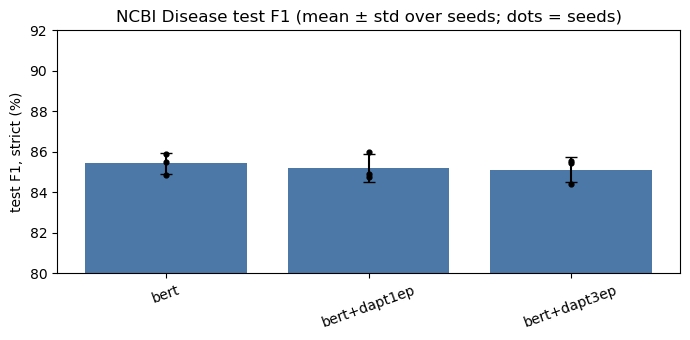

In [3]:
order = list(summary.index)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(order, summary[("F1", "mean")], yerr=summary[("F1", "std")], capsize=4, color="#4C78A8")
for i, m in enumerate(order):
    ax.scatter([i] * (runs.model == m).sum(), runs[runs.model == m].F1, color="black", s=12, zorder=3)
ax.set(ylabel="test F1, strict (%)", title="NCBI Disease test F1 (mean ± std over seeds; dots = seeds)")
ax.set_ylim(80, 92)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Three-model comparison as presented (single run per model).** These are the test-set scores shown on the
presentation slide (runs by Yuanquan Jin and Bai Li). They are single runs, so they are not directly comparable
with the 3-seed means above; for example BERT is 85.28 here and 85.43 ± 0.51 in the unified 3-seed table.
TODO: replace with per-seed metric files from the unified framework if they are available before submission.

,P,R,F1,token acc
model,,,,
BERT-base-cased,82.62,88.13,85.28,98.39
BioBERT,85.97,90.00,87.94,98.61
PubMedBERT,85.63,89.38,87.46,98.58


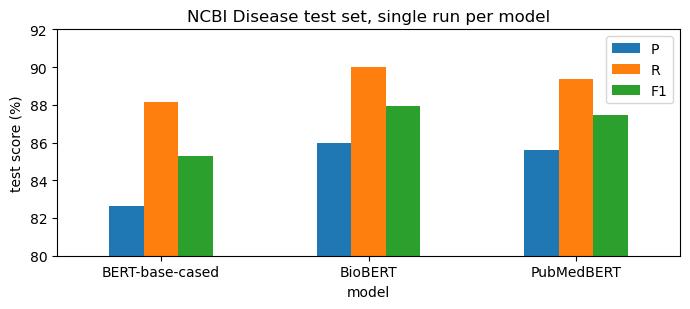

In [4]:
presented = pd.DataFrame(
    [["BERT-base-cased", 82.62, 88.13, 85.28, 98.39],
     ["BioBERT", 85.97, 90.00, 87.94, 98.61],
     ["PubMedBERT", 85.63, 89.38, 87.46, 98.58]],
    columns=["model", "P", "R", "F1", "token acc"]).set_index("model")
display(presented)
ax = presented[["P", "R", "F1"]].plot.bar(figsize=(7, 3.2), ylim=(80, 92), rot=0)
ax.set(ylabel="test score (%)", title="NCBI Disease test set, single run per model")
plt.tight_layout()
plt.show()

**Comparison with published results.** Fill in from the papers, and say how their protocol differs from ours
(e.g. number of runs, train+dev training, metric):

| Model | Published F1 on NCBI Disease | Source | Ours (mean ± std) |
|---|---|---|---|
| BERT | TODO | Lee et al., 2020 | from table above |
| BioBERT v1.1 | 89.71 | Lee et al., 2020, Table 6 | 87.94 (single run) |
| PubMedBERT | 87.82 | Gu et al., 2021 | 87.46 (single run) |

## Discussion and error analysis
*Owners: Alex Shen, Chongli Chen. Rubric (2 marks): insight into performance, strengths, weaknesses, limitations,
future work.*

In [5]:
text = Path("dapt/results/error_analysis_dapt3ep.md").read_text()
print(text.split("### Stable differences")[0])

Entity-level error analysis, `bert+dapt3ep` vs `bert`, split `test`, seeds 1, 2, 3. Strict IOB2 entities (as seqeval mode='strict'); counts are checked against each run's metrics.json. 940 sentences, 960 gold entities.

FP boundary = predicted entity overlaps a gold entity but the span differs; FP spurious = no overlap with any gold entity. FN boundary = gold entity overlaps a predicted entity; FN missed = no overlap. One predicted span can overlap two gold spans (and vice versa), so FP boundary and FN boundary need not be equal. P / R / F1 in the `all` rows are pooled over seeds (micro), so they can differ in the second decimal from the mean over seeds in results.md. `tokens` = start-end (end exclusive) token offsets.

### Totals over seeds

| label | seed | TP | FP | FP boundary | FP spurious | FN | FN boundary | FN missed | P | R | F1 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| bert | all | 2495 | 466 | 234 | 232 | 385 | 212 | 173 | 84.26 | 86.63 | 85.43 |
| ber

Points to cover:
- Biomedical pre-training vs general BERT: size of the gain, and where it comes from (vocabulary, abbreviations).
- DAPT: the model did adapt (perplexity 6.9 to 3.4), yet NER F1 did not change beyond seed noise. Likely reasons:
  the corpus is small (about 10 M tokens vs billions for BioBERT/PubMedBERT); the NCBI training set already
  supplies the in-domain signal NER needs.
- Error types: boundary errors vs spurious / missed mentions; ambiguous abbreviations.
- Limitations: one dataset, three seeds, one hyper-parameter setting, small DAPT corpus.
- Future work: larger DAPT corpus or task-adaptive pre-training, other datasets (BC5CDR), CRF head, LLM prompting baseline.

## Conclusion
One paragraph: what we built, the main numbers, the answer to each question in section 1.

## References
- Doğan, R. I., Leaman, R., Lu, Z. (2014). NCBI disease corpus. *Journal of Biomedical Informatics*.
- Devlin, J. et al. (2019). BERT. *NAACL*.
- Lee, J. et al. (2020). BioBERT. *Bioinformatics*.
- Gu, Y. et al. (2021). Domain-specific language model pretraining for biomedical NLP (PubMedBERT). *ACM HEALTH*.
- Gururangan, S. et al. (2020). Don't stop pretraining. *ACL*.

## Appendix: how the saved metrics were produced
Not executed here (about 13 minutes per run on an Apple M-series GPU). From the repository root:

```bash
python audit_ncbi_splits.py --no-hf --conll_dir data/ncbi_disease
python -m ner.sweep --models bert biobert pubmedbert --seeds 1 2 3 --runs_dir runs/final
python -m ner.aggregate runs/final --out runs/final/results.md
python -m ner.dapt --model bert --epochs 3 --output_dir runs_dapt/bert_dapt_3ep
python -m ner.sweep --models bert --seeds 1 2 3 --init_from runs_dapt/bert_dapt_3ep/model --label bert+dapt3ep
```